### Dans ce notebook nous allons charger les modèles que nous avons entrainés et réaliser des prédictions visuelles des masques en utilisant les couleurs pour montrer aussi les zones où ils se trompent, indiquer le pourcentage de faute (ce qui revient à rejoindre la matrice de confusion mais ceci de manière visuelle)

Nous allons en local mettre ces modèles .pth dans le dossier "models", nous prendrons le soin de renommer les fichier comme il se doit afin de ne pas confondre.

Pour le moment comme nous n'avons pas encore réaliser entièrement les expérimentations (nous sommes encore au niveau de la comparaison entre les fonctions de perte sur un split unique, nous n'avons pas encore expérimenté les méthodes d'augmentation ni les méthodes de prétraitement, ni la validation k-fold) 

Les modèles que nous allons chargé ici seront les meilleurs modèles dont la comparaison est basée sur la fonction de perte. L'augmentation effectué est standard (contraste+luminosité), pas de prétraitement et pas de k-fold 

In [3]:
# ============================================================
# CELLULE 1 — Imports & configuration
# ============================================================
import os
import sys
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from transformers import SegformerForSemanticSegmentation

# --- Chemins (adapte PREDICTIONS_ROOT si besoin) ---
PREDICTIONS_ROOT = Path(r"C:\M2_USPN\Projet_Stage_M2\implémentations\predictions")
MODELS_DIR   = PREDICTIONS_ROOT / "models"
DATASET_DIR  = PREDICTIONS_ROOT.parent / "Dataset"
TESTING_IMGS = DATASET_DIR / "testing" / "images"
TESTING_MSKS = DATASET_DIR / "testing" / "gt_images"
OUTPUT_DIR   = PREDICTIONS_ROOT / "visualisations"
OUTPUT_DIR.mkdir(exist_ok=True)

# --- Paramètres identiques aux notebooks d'entraînement ---
IMG_H, IMG_W = 352, 480
N_CLASSES    = 2
DEVICE       = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Modèles disponibles (nom_affichage : fichier .pth) ---
MODELS_CONFIG = {
    "FCN-8s VGG16"    : MODELS_DIR / "7A_fcn8vgg16_ce_best.pth",
    "SegFormer-B1"    : MODELS_DIR / "7A_segformerb1_ce_best.pth",
    "SegFormer-B2"    : MODELS_DIR / "7A_segformerb2_ce_best.pth",
}

print(f"Device  : {DEVICE}")
print(f"Images  : {TESTING_IMGS}")
print(f"Modèles : {MODELS_DIR}")
for name, path in MODELS_CONFIG.items():
    status = "OK" if path.exists() else "KO: INTROUVABLE"
    print(f"  [{status}] {name} — {path.name}")

Device  : cpu
Images  : C:\M2_USPN\Projet_Stage_M2\implémentations\Dataset\testing\images
Modèles : C:\M2_USPN\Projet_Stage_M2\implémentations\predictions\models
  [OK] FCN-8s VGG16 — 7A_fcn8vgg16_ce_best.pth
  [OK] SegFormer-B1 — 7A_segformerb1_ce_best.pth
  [OK] SegFormer-B2 — 7A_segformerb2_ce_best.pth


## Définition des architectures et chargement des modèles 

In [10]:
# ============================================================
# CELLULE 2 — Architectures + chargement des .pth
# ============================================================
import torchvision.models as models
from transformers import SegformerForSemanticSegmentation

# ---------- FCN-8s VGG16 (architecture exacte du fcn_tutoriel) ----------
class FCNVGG16(nn.Module):
    def __init__(self, in_channels=3, n_classes=2, base_channels=None, pretrained=False):
        super().__init__()
        self.n_classes = n_classes

        self.register_buffer('img_mean',
                             torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('img_std',
                             torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        # Encodeur VGG16
        weights = models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None
        vgg = models.vgg16(weights=weights)
        f = list(vgg.features.children())

        self.block1 = nn.Sequential(*f[0:5])    # -> 1/2
        self.block2 = nn.Sequential(*f[5:10])   # -> 1/4
        self.block3 = nn.Sequential(*f[10:17])  # -> 1/8
        self.block4 = nn.Sequential(*f[17:24])  # -> 1/16
        self.block5 = nn.Sequential(*f[24:31])  # -> 1/32

        # Tête fully-convolutional (fc6, fc7 convertis)
        self.fc_conv = nn.Sequential(
            nn.Conv2d(512, 4096, kernel_size=7, padding=3),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.5),
            nn.Conv2d(4096, 4096, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.5),
        )

        # Scores par classe à différentes résolutions
        self.score_main  = nn.Conv2d(4096, n_classes, kernel_size=1)
        self.score_pool4 = nn.Conv2d(512,  n_classes, kernel_size=1)
        self.score_pool3 = nn.Conv2d(256,  n_classes, kernel_size=1)

        # Déconvolutions FCN-8s
        self.upscore2      = nn.ConvTranspose2d(n_classes, n_classes, kernel_size=4,
                                                stride=2, padding=1)
        self.upscore_pool4 = nn.ConvTranspose2d(n_classes, n_classes, kernel_size=4,
                                                stride=2, padding=1)
        self.upscore8      = nn.ConvTranspose2d(n_classes, n_classes, kernel_size=16,
                                                stride=8, padding=4)

    def forward(self, x):
        input_size = x.shape[2:]
        x = (x - self.img_mean) / self.img_std

        x     = self.block1(x)
        x     = self.block2(x)
        pool3 = self.block3(x)
        pool4 = self.block4(pool3)
        pool5 = self.block5(pool4)

        h = self.fc_conv(pool5)
        h = self.score_main(h)

        h = self.upscore2(h)
        score_p4 = self.score_pool4(pool4)
        if h.shape[2:] != score_p4.shape[2:]:
            h = F.interpolate(h, size=score_p4.shape[2:], mode='bilinear', align_corners=False)
        h = h + score_p4

        h = self.upscore_pool4(h)
        score_p3 = self.score_pool3(pool3)
        if h.shape[2:] != score_p3.shape[2:]:
            h = F.interpolate(h, size=score_p3.shape[2:], mode='bilinear', align_corners=False)
        h = h + score_p3

        h = self.upscore8(h)
        if h.shape[2:] != input_size:
            h = F.interpolate(h, size=input_size, mode='bilinear', align_corners=False)
        return h


# ---------- SegFormer (architecture exacte du segformer_tutoriel) ----------
class SegFormer(nn.Module):
    def __init__(self, n_classes=2, variant='b2', pretrained=False):
        super().__init__()
        self.register_buffer('img_mean',
                             torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('img_std',
                             torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        if pretrained:
            self.model = SegformerForSemanticSegmentation.from_pretrained(
                f'nvidia/mit-{variant}', num_labels=n_classes,
                ignore_mismatched_sizes=True)
        else:
            config_hf = SegformerForSemanticSegmentation.config_class.from_pretrained(
                f'nvidia/mit-{variant}', num_labels=n_classes,
                ignore_mismatched_sizes=True)
            self.model = SegformerForSemanticSegmentation(config_hf)

    def forward(self, x):
        input_size = x.shape[-2:]
        x = (x - self.img_mean) / self.img_std
        logits = self.model(pixel_values=x).logits
        return F.interpolate(logits, size=input_size,
                             mode='bilinear', align_corners=False)


# ---------- Chargement générique depuis .pth ----------
def load_model(name, pth_path):
    checkpoint = torch.load(pth_path, map_location=DEVICE, weights_only=False)

    # Détection de la bonne clé selon le format du checkpoint
    if 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
    elif 'state_dict' in checkpoint:
        state_dict = checkpoint['state_dict']
    else:
        state_dict = checkpoint  # sauvegarde directe du state_dict

    fname = pth_path.name.lower()
    if 'segformer' in fname:
        variant = 'b1' if 'b1' in fname else 'b2' if 'b2' in fname else 'b0'
        model = SegFormer(n_classes=N_CLASSES, variant=variant, pretrained=True)
    else:
        model = FCNVGG16(n_classes=N_CLASSES, pretrained=False)

    model.load_state_dict(state_dict, strict=True)
    model.to(DEVICE).eval()
    print(f"  OK: {name} chargé ({pth_path.name})")
    return model


# --- Chargement de tous les modèles ---
print("=== Chargement des modèles ===")
models_dict = {}
for name, pth_path in MODELS_CONFIG.items():
    if pth_path.exists():
        models_dict[name] = load_model(name, pth_path)
    else:
        print(f"  KO: {name} ignoré (fichier introuvable)")

print(f"\n{len(models_dict)} modèle(s) prêt(s) : {list(models_dict.keys())}")

=== Chargement des modèles ===
  OK: FCN-8s VGG16 chargé (7A_fcn8vgg16_ce_best.pth)


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  OK: SegFormer-B1 chargé (7A_segformerb1_ce_best.pth)


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down

  OK: SegFormer-B2 chargé (7A_segformerb2_ce_best.pth)

3 modèle(s) prêt(s) : ['FCN-8s VGG16', 'SegFormer-B1', 'SegFormer-B2']


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


## Les prédictions sur quelques données de test

In [27]:
# ============================================================
# CELLULE 3 — Prédiction + visualisation colorée
#
# Configuration identique à la Section 7 des tutoriels :
#   - Résolution  : 352 × 480
#   - Prétraitement : aucun (preprocess=None)
#   - Augmentation  : non appliquée sur le testing set
#   - Normalisation : ImageNet intégrée dans chaque modèle

# Palette de couleurs pour l'overlay
# vert  = vrai positif  (posidonie bien détectée)
# rouge = faux positif  (prédit posidonie, c'est fond)
# bleu  = faux négatif  (prédit fond, c'est posidonie)
# noir  = vrai négatif  (fond bien classifié) -> transparent
# ============================================================



COLORS = {
    'TP': np.array([0,   200,   0], dtype=np.uint8),   # vert
    'FP': np.array([220,   0,   0], dtype=np.uint8),   # rouge
    'FN': np.array([0,    80, 220], dtype=np.uint8),   # bleu
    'TN': np.array([0,     0,   0], dtype=np.uint8),   # noir (masqué)
}
ALPHA = 0.55   # transparence de l'overlay


def preprocess_image(img_path):
    """Charge et resize une image → tenseur [1, 3, H, W] float en [0,1]."""
    img = Image.open(img_path).convert('RGB')
    img = img.resize((IMG_W, IMG_H), Image.BILINEAR)
    return transforms.ToTensor()(img).unsqueeze(0)   # [1, 3, H, W]


def load_gt_mask(mask_path):
    """Charge le masque GT (grayscale testing) → np.ndarray {0,1}."""
    mask = Image.open(mask_path).convert('L')
    mask = mask.resize((IMG_W, IMG_H), Image.NEAREST)
    return (np.array(mask) > 127).astype(np.uint8)


def predict(model, img_tensor):
    """Prédit le masque binaire {0,1} pour une image."""
    with torch.no_grad():
        logits = model(img_tensor.to(DEVICE))          # [1, 2, H, W]
        pred   = logits.argmax(dim=1).squeeze(0)       # [H, W]
    return pred.cpu().numpy().astype(np.uint8)


def make_overlay(img_rgb, pred_mask, gt_mask):
    """
    Crée un overlay coloré montrant TP/FP/FN sur l'image originale.
    Retourne l'image RGB avec overlay.
    """
    overlay = img_rgb.copy().astype(np.float32)
    color_map = np.zeros_like(img_rgb, dtype=np.uint8)
    alpha_map = np.zeros(img_rgb.shape[:2], dtype=np.float32)

    tp = (pred_mask == 1) & (gt_mask == 1)
    fp = (pred_mask == 1) & (gt_mask == 0)
    fn = (pred_mask == 0) & (gt_mask == 1)

    for mask, key in [(tp, 'TP'), (fp, 'FP'), (fn, 'FN')]:
        color_map[mask] = COLORS[key]
        alpha_map[mask] = ALPHA

    alpha_3d = alpha_map[:, :, np.newaxis]
    blended  = (1 - alpha_3d) * overlay + alpha_3d * color_map.astype(np.float32)
    return np.clip(blended, 0, 255).astype(np.uint8)


def compute_metrics(pred_mask, gt_mask):
    """Calcule TP/FP/FN/TN et les métriques principales."""
    tp = int(((pred_mask == 1) & (gt_mask == 1)).sum())
    fp = int(((pred_mask == 1) & (gt_mask == 0)).sum())
    fn = int(((pred_mask == 0) & (gt_mask == 1)).sum())
    tn = int(((pred_mask == 0) & (gt_mask == 0)).sum())
    total = tp + fp + fn + tn

    precision = tp / (tp + fp + 1e-8)
    recall    = tp / (tp + fn + 1e-8)
    f1        = 2 * precision * recall / (precision + recall + 1e-8)
    iou       = tp / (tp + fp + fn + 1e-8)
    accuracy  = (tp + tn) / (total + 1e-8)

    pct = lambda x: f"{100*x/total:.1f}%"
    return {
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        'pct_TP': pct(tp), 'pct_FP': pct(fp), 'pct_FN': pct(fn),
        'precision': precision, 'recall': recall,
        'F1': f1, 'IoU': iou, 'accuracy': accuracy,
    }


def visualize_predictions(img_name, models_dict, save=True):
    """
    Pour une image donnée, affiche côte à côte :
      image originale | GT | overlay modèle 1 | overlay modèle 2 | ...
    """
    # Chemins
    img_path  = TESTING_IMGS / img_name
    base      = img_name.replace('.png', '').replace('.jpg', '')
    mask_name = base + '_gt.png'
    mask_path = TESTING_MSKS / mask_name

    if not img_path.exists():
        print(f"Image introuvable : {img_path}"); return
    if not mask_path.exists():
        print(f"Masque introuvable : {mask_path}"); return

    # Chargement
    img_tensor = preprocess_image(img_path)
    gt_mask    = load_gt_mask(mask_path)
    img_rgb    = np.array(Image.open(img_path).convert('RGB')
                          .resize((IMG_W, IMG_H), Image.BILINEAR))

    n_cols = 2 + len(models_dict)   # original + GT + 1 par modèle
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 5))
    fig.suptitle(f"{base}", fontsize=13, fontweight='bold')

    # Col 0 : image originale
    axes[0].imshow(img_rgb)
    axes[0].set_title("Image originale", fontsize=10)
    axes[0].axis('off')

    # Col 1 : masque GT
    gt_display = np.zeros((*gt_mask.shape, 4), dtype=np.uint8)  # RGBA
    gt_display[gt_mask == 1] = [0, 200, 0, 180]   # vert semi-transparent
    gt_display[gt_mask == 0] = [0,   0, 0,   0]   # fond totalement transparent
    axes[1].imshow(img_rgb)
    axes[1].imshow(gt_display)
    axes[1].set_title("Masque GT", fontsize=10)
    axes[1].axis('off')

    # Cols suivantes : un par modèle
    for col, (name, model) in enumerate(models_dict.items(), start=2):
        pred    = predict(model, img_tensor)
        overlay = make_overlay(img_rgb, pred, gt_mask)
        m       = compute_metrics(pred, gt_mask)

        axes[col].imshow(overlay)
        title = (f"{name}\n"
                 f"F1={m['F1']:.3f}  IoU={m['IoU']:.3f}\n"
                 f"FP={m['pct_FP']}  FN={m['pct_FN']}")
        axes[col].set_title(title, fontsize=9)
        axes[col].axis('off')

    # Légende
    legend_patches = [
        mpatches.Patch(color=np.array(COLORS['TP'])/255, label=f"TP — posidonie détectée"),
        mpatches.Patch(color=np.array(COLORS['FP'])/255, label=f"FP — fausse alarme"),
        mpatches.Patch(color=np.array(COLORS['FN'])/255, label=f"FN — posidonie manquée"),
    ]
    fig.legend(handles=legend_patches, loc='lower center',
               ncol=3, fontsize=9, framealpha=0.8,
               bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()

    if save:
        out_path = OUTPUT_DIR / f"{base}_comparison.png"
        plt.savefig(out_path, dpi=150, bbox_inches='tight')
        print(f"  Sauvegardé : {out_path.name}")

    plt.show()
    plt.close()


def visualize_individual(img_name, models_dict, save=True):
    """
    Sauvegarde chaque panneau séparément :
      {base}_original.png
      {base}_GT.png
      {base}_{nom_modele}.png  (un par modèle)
    """
    # Chemins
    img_path  = TESTING_IMGS / img_name
    base      = img_name.replace('.png', '').replace('.jpg', '')
    mask_path = TESTING_MSKS / (base + '_gt.png')

    if not img_path.exists():
        print(f"Image introuvable : {img_path}"); return
    if not mask_path.exists():
        print(f"Masque introuvable : {mask_path}"); return

    img_tensor = preprocess_image(img_path)
    gt_mask    = load_gt_mask(mask_path)
    img_rgb    = np.array(Image.open(img_path).convert('RGB')
                          .resize((IMG_W, IMG_H), Image.BILINEAR))

    def save_fig(ax_fn, filename):
        fig, ax = plt.subplots(1, 1, figsize=(5, 4))
        ax_fn(ax)
        ax.axis('off')
        plt.tight_layout(pad=0)
        if save:
            out = OUTPUT_DIR / filename
            plt.savefig(out, dpi=200, bbox_inches='tight', pad_inches=0)
            print(f"  Sauvegardé : {out.name}")
        plt.show()
        plt.close()

    # --- Image originale ---
    def plot_original(ax):
        ax.imshow(img_rgb)
        ax.set_title("Image originale", fontsize=11)
    save_fig(plot_original, f"{base}_original.png")

    # --- Masque GT ---
    def plot_gt(ax):
        gt_display = np.zeros((*gt_mask.shape, 4), dtype=np.uint8)  # RGBA
        gt_display[gt_mask == 1] = [0, 200, 0, 180]   # vert semi-transparent
        gt_display[gt_mask == 0] = [0,   0, 0,   0]   # fond totalement transparent
        ax.imshow(img_rgb)
        ax.imshow(gt_display)
        ax.set_title("Masque GT", fontsize=11)
    save_fig(plot_gt, f"{base}_GT.png")

    # --- Un panneau par modèle ---
    for i, (model_name, model) in enumerate(models_dict.items()):
        pred    = predict(model, img_tensor)
        overlay = make_overlay(img_rgb, pred, gt_mask)
        m       = compute_metrics(pred, gt_mask)

        safe_name = model_name.replace(' ', '_').replace('/', '-')

        def plot_model(ax, overlay=overlay, m=m, model_name=model_name, i=i):
            ax.imshow(overlay)
            ax.set_title(
                f"{model_name}\n"
                f"F1={m['F1']:.3f}  IoU={m['IoU']:.3f}\n"
                f"FP={m['pct_FP']}  FN={m['pct_FN']}",
                fontsize=10
            )
            # Légende uniquement sur le premier modèle
            if i == 0:
                legend_patches = [
                    mpatches.Patch(color=np.array(COLORS['TP'])/255,
                                   label="TP - posidonie détectée"),
                    mpatches.Patch(color=np.array(COLORS['FP'])/255,
                                   label="FP - fausse alarme"),
                    mpatches.Patch(color=np.array(COLORS['FN'])/255,
                                   label="FN - posidonie manquée"),
                ]
                ax.legend(handles=legend_patches, loc='lower center',
                          fontsize=8, framealpha=0.85,
                          bbox_to_anchor=(0.5, -0.18), ncol=3)

        save_fig(plot_model, f"{base}_{safe_name}.png")
        
print(" Fonctions de visualisation prêtes")

 Fonctions de visualisation prêtes



-> calablava_000063.png
  Sauvegardé : calablava_000063_comparison.png


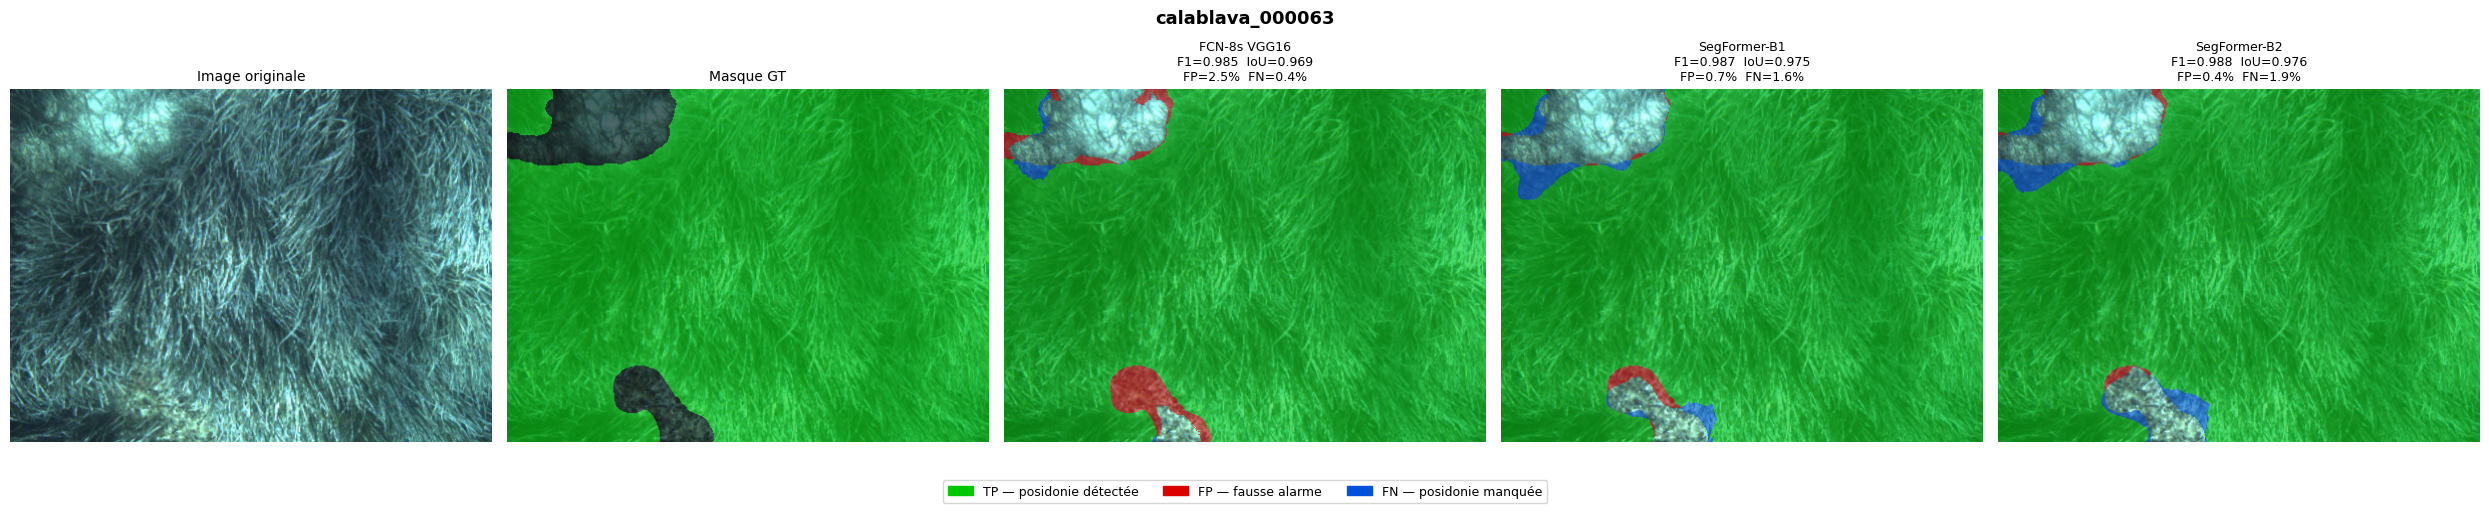


-> calablava_000100.png
Image introuvable : C:\M2_USPN\Projet_Stage_M2\implémentations\Dataset\testing\images\calablava_000100.png

-> calablava_000150.png
Image introuvable : C:\M2_USPN\Projet_Stage_M2\implémentations\Dataset\testing\images\calablava_000150.png

OK: Visualisations sauvegardées dans : C:\M2_USPN\Projet_Stage_M2\implémentations\predictions\visualisations


In [18]:
# ============================================================
# CELLULE 4 — Lancement
# ============================================================

# --- Option A : sur quelques images choisies manuellement ---
images_a_visualiser = [
    "calablava_000063.png",
    "calablava_000100.png",
    "calablava_000150.png",
]

for img_name in images_a_visualiser:
    print(f"\n-> {img_name}")
    visualize_predictions(img_name, models_dict, save=True)

# --- Option B : sur toutes les images du testing set (décommenter) ---
# all_imgs = sorted([f.name for f in TESTING_IMGS.iterdir()
#                    if f.suffix.lower() in ('.png', '.jpg')])
# print(f"{len(all_imgs)} images trouvées")
# for img_name in all_imgs:
#     visualize_predictions(img_name, models_dict, save=True)

print(f"\nOK: Visualisations sauvegardées dans : {OUTPUT_DIR}")


-> calablava_000155.png
  Sauvegardé : calablava_000155_comparison.png


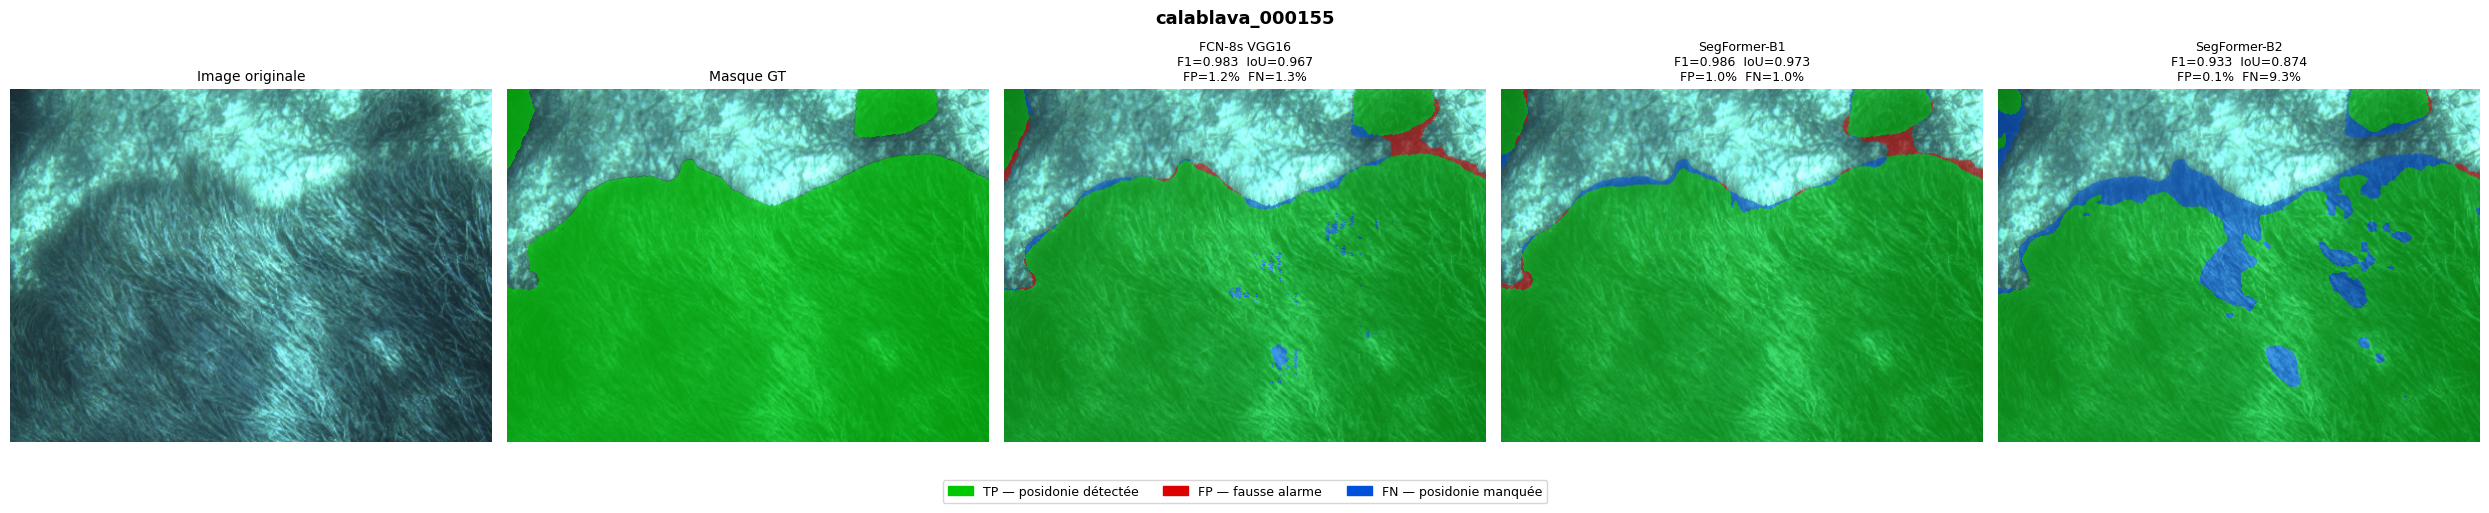

  Sauvegardé : calablava_000155_original.png


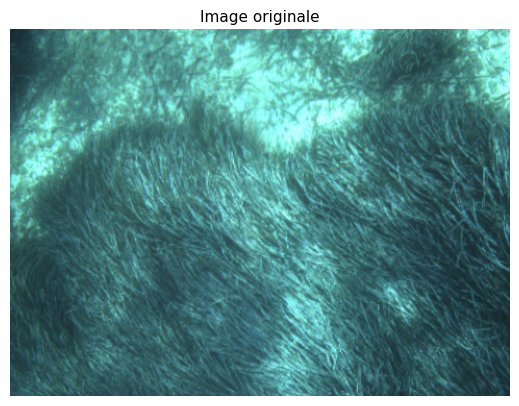

  Sauvegardé : calablava_000155_GT.png


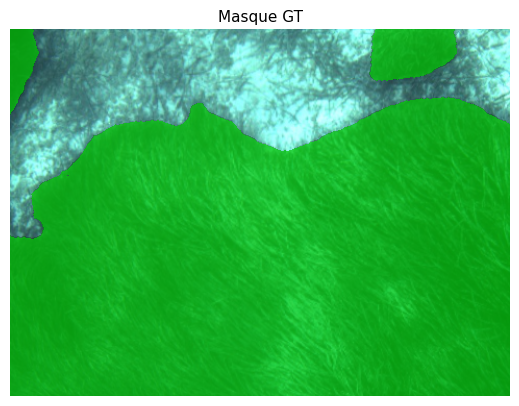

  Sauvegardé : calablava_000155_FCN-8s_VGG16.png


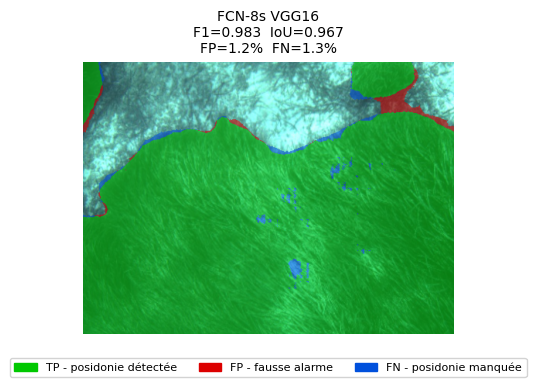

  Sauvegardé : calablava_000155_SegFormer-B1.png


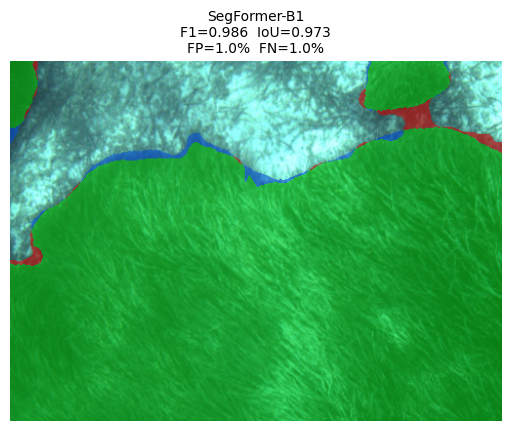

  Sauvegardé : calablava_000155_SegFormer-B2.png


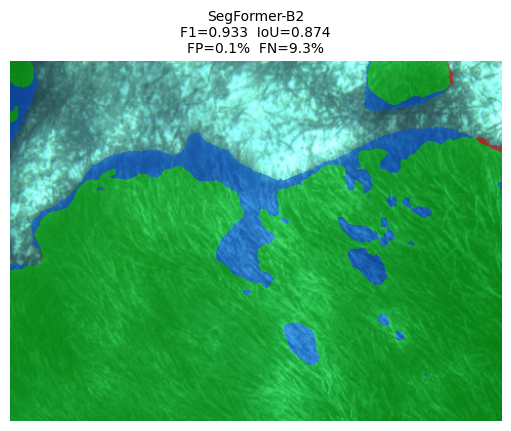

In [31]:
images_a_visualiser = [
    "calablava_000155.png",
]

for img_name in images_a_visualiser:
    print(f"\n-> {img_name}")
    visualize_predictions(img_name, models_dict, save=True)   # vue combinée
    visualize_individual(img_name, models_dict, save=True)    # panneaux séparés